è finito? True
è non negativo? True
Valore in x=0: 515.0
Valore atteso B + I0: 515


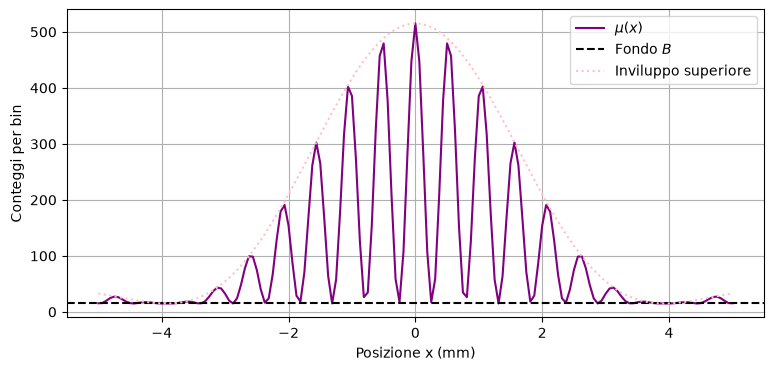

In [2]:
!pip install numpy matplotlib
import numpy as np
import matplotlib.pyplot as plt

B=15 #fondo uniforme
I0=500 #scala del segnale
alpha=0.80 #larghezza inviluppo (mm-1)
delta=6.00 #frequenza spaziale delle frange
x = np.linspace(-5.0, 5.0, 161)

E_x = np.sinc(alpha * x / np.pi)**2
C_x = np.cos(delta * x)**2
mu_x = B + I0 * E_x * C_x        

#attività 1

print("è finito?", np.all(np.isfinite(mu_x))) #verifica se mu sia finita, deve dare true
print("è non negativo?", np.all(mu_x >= 0)) #verifica se mu è non negativa. deve dare true
print("Valore in x=0:", mu_x[80]) # Indice centrale 
print("Valore atteso B + I0:", B + I0) # Devono essere compatibili

plt.figure(figsize=(9, 4)) #dimensioni grafico
plt.plot(x, mu_x, label=r'$\mu(x)$', color='purple') #curva mu_x
plt.axhline(B, color='black', linestyle='--', label='Fondo $B$') #linea orizzontale all'altezza di B
plt.plot(x, B + I0 * E_x, color='pink', linestyle=':', label='Inviluppo superiore') #curva inviluppo
plt.xlabel('Posizione x (mm)') #etichetta asse x
plt.ylabel('Conteggi per bin') #etichetta asse y
plt.legend() #aggiunge la legenda
plt.grid(True) #aggiunge la griglia
plt.show() #stampa il grafico

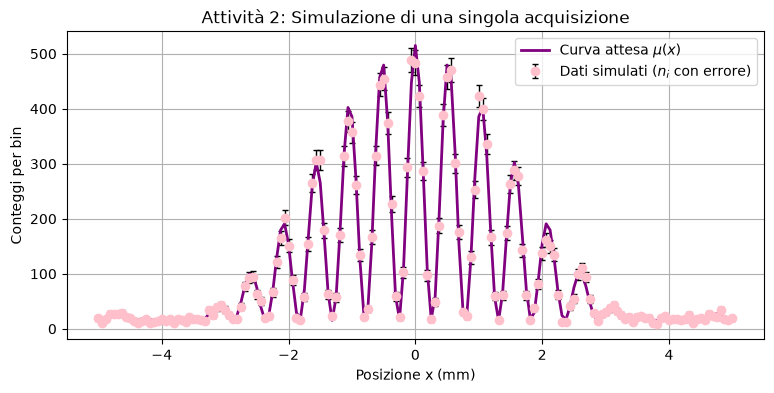

Conteggi nella regione centrale (Nc): 9722
Valore atteso nella regione centrale (muc): 9825.72
Differenza assoluta (Nc - muc): 103.72
Incertezza statistica attesa (sqrt(muc)): 99.12
Rapporto (differenza/incertezza) :  1.05
La differenza è compatibile con una fluttuazione statistica (rapporto<=2).


In [5]:
#Attività 2: simulazione di un'acquisizione
rng = np.random.default_rng(42) #generatore di numeri casuali locale
n_i = rng.poisson(mu_x)

errori = np.sqrt(n_i)
errori[errori == 0] = 1.0

plt.figure(figsize=(9, 4))
plt.errorbar(x, n_i, yerr=errori, fmt='o', color='pink', ecolor='black', 
             elinewidth=1, capsize=2, label='Dati simulati ($n_i$ con errore)')
plt.plot(x, mu_x, color='purple', linewidth=2, label=r'Curva attesa $\mu(x)$')
plt.xlabel('Posizione x (mm)')
plt.ylabel('Conteggi per bin')
plt.title('Attività 2: Simulazione di una singola acquisizione')
plt.legend()
plt.grid(True)
plt.show()

regione_centrale = np.abs(x) < 1.2
Nc = np.sum(n_i[regione_centrale])
muc = np.sum(mu_x[regione_centrale])

differenza_assoluta = abs(Nc - muc)
sigma_attesa = np.sqrt(muc)
rapporto= differenza_assoluta / sigma_attesa

print(f"Conteggi nella regione centrale (Nc): {Nc}")
print(f"Valore atteso nella regione centrale (muc): {muc:.2f}")
print(f"Differenza assoluta (Nc - muc): {differenza_assoluta:.2f}")
print(f"Incertezza statistica attesa (sqrt(muc)): {sigma_attesa:.2f}")
print(f"Rapporto (differenza/incertezza) : {differenza_assoluta / sigma_attesa: .2f}")

if rapporto <= 2.0:
    print( "La differenza è compatibile con una fluttuazione statistica (rapporto<=2).")
else:
    print( "La differenza è superiore a un normale scarto statistico (rapporto>2).")
    


In [ ]:
#Attività 3

M = 2000

matrice_conteggi = rng.poisson(lam=mu_x, size=(M, len(x)))

regione_centrale = np.abs(x) < 1.2

Nc_array = np.sum(matrice_conteggi[:, regione_centrale], axis=1)

media_simulata = np.mean(Nc_array)
dev_std_simulata = np.std(Nc_array, ddof=1)
errore_sulla_media = dev_std_simulata / np.sqrt(M)
scarto_relativo = abs(media_simulata - muc) / muc

print(f"Media simulata di Nc: {media_simulata:.2f}")
print(f"Valore atteso teorico (muc): {muc:.2f}")
print(f"Deviazione standard simulata (sigma_Nc): {dev_std_simulata:.2f}")
print(f"Incertezza teorica attesa (sqrt(muc)): {np.sqrt(muc):.2f}")
print(f"Errore sulla media: {errore_sulla_media:.3f}")
print(f"Scarto relativo: {scarto_relativo:.5f}")

plt.figure(figsize=(9, 4))
plt.hist(Nc_array, bins=30, density=True, color='lightblue', edgecolor='black', alpha=0.7, label='Distribuzione di $N_c$')
plt.axvline(media_simulata, color='red', linestyle='-', linewidth=2, label=f'Media simulata ({media_simulata:.1f})')
plt.axvline(muc, color='green', linestyle='--', linewidth=2, label=f'Valore atteso $\mu_c$ ({muc:.1f})')
plt.xlabel('Valori di $N_c$')
plt.ylabel('Densità di probabilità')
plt.title('Attività 3: Distribuzione dello stimatore $N_c$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

s        | Media Nc     | Dev. Std     | r(s)         | r(s)*sqrt(s)
-----------------------------------------------------------------
0.25     | 2456.62      | 50.46        | 0.0205       | 0.0103      
0.5      | 4910.79      | 69.40        | 0.0141       | 0.0100      
1        | 9823.58      | 100.63       | 0.0102       | 0.0102      
2        | 19650.03     | 137.85       | 0.0070       | 0.0099      
4        | 39297.91     | 196.96       | 0.0050       | 0.0100      
8        | 78606.43     | 280.96       | 0.0036       | 0.0101      


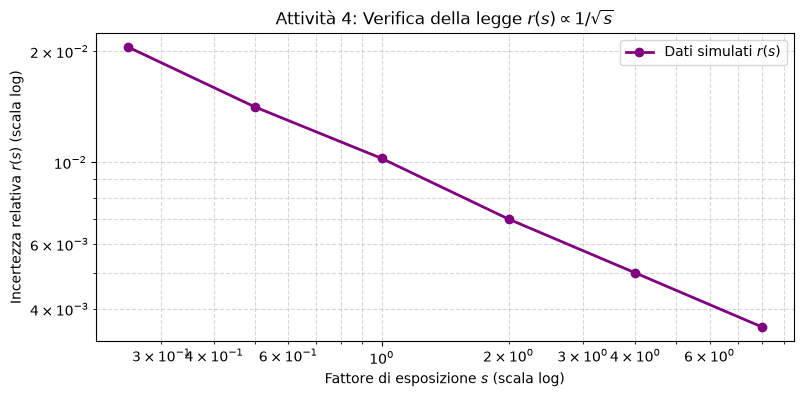

In [6]:
#Attività 4
valori_s = [0.25, 0.5, 1, 2, 4, 8] #valori fattore esposizione
M_stat = 1000  # Numero di pseudo-esperimenti per ogni s

s_list = []
media_list = []
std_list = []
r_list = []
r_sqrt_s_list = []

regione_centrale = np.abs(x) < 1.2

for s in valori_s:
    mu_s = s * mu_x
    matrice_s = rng.poisson(lam=mu_s, size=(M_stat, len(x)))
    Nc_s = np.sum(matrice_s[:, regione_centrale], axis=1)
    media_Nc = np.mean(Nc_s)
    std_Nc = np.std(Nc_s, ddof=1)
    r_s = std_Nc / media_Nc
    r_times_sqrt_s = r_s * np.sqrt(s)
    s_list.append(s)
    media_list.append(media_Nc)
    std_list.append(std_Nc)
    r_list.append(r_s)
    r_sqrt_s_list.append(r_times_sqrt_s)

print(f"{'s':<8} | {'Media Nc':<12} | {'Dev. Std':<12} | {'r(s)':<12} | {'r(s)*sqrt(s)':<12}")
print("-" * 65)
for i in range(len(valori_s)):
    print(f"{s_list[i]:<8} | {media_list[i]:<12.2f} | {std_list[i]:<12.2f} | {r_list[i]:<12.4f} | {r_sqrt_s_list[i]:<12.4f}")

plt.figure(figsize=(9, 4))
plt.loglog(valori_s, r_list, marker='o', color='purple', linestyle='-', linewidth=2, label='Dati simulati $r(s)$')
plt.xlabel('Fattore di esposizione $s$ (scala log)')
plt.ylabel('Incertezza relativa $r(s)$ (scala log)')
plt.title(r'Attività 4: Verifica della legge $r(s) \propto 1/\sqrt{s}$')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()